In [1]:
import pandas as pd

cluster1 = pd.read_csv('./results/PPI/cluster1_annotations.tsv', sep='\t')
print(cluster1.columns.tolist())
print(cluster1.head())

['#node', 'identifier', 'domain_summary_url', 'annotation', 'other_names_and_aliases']
       #node            identifier  \
0  ARHGAP11A  9606.ENSP00000355090   
1      ASF1B  9606.ENSP00000263382   
2       ASPM  9606.ENSP00000356379   
3      ATAD2  9606.ENSP00000287394   
4      AURKA  9606.ENSP00000216911   

                                  domain_summary_url  \
0                 Rho GTPase activating protein 11A.   
1  Histone chaperone ASF1B; Histone chaperone tha...   
2  Abnormal spindle-like microcephaly-associated ...   
3  ATPase family AAA domain-containing protein 2;...   
4  Aurora kinase A; Mitotic serine/threonine kina...   

                                          annotation  \
0  https://smart.embl.de/smart/DDvec.cgi?smart=10...   
1  https://smart.embl.de/smart/DDvec.cgi?smart=20...   
2  https://smart.embl.de/smart/DDvec.cgi?smart=34...   
3  https://smart.embl.de/smart/DDvec.cgi?smart=13...   
4  https://smart.embl.de/smart/DDvec.cgi?smart=40...   

          

In [3]:
# Extract gene list from cluster 1
cluster1_genes = cluster1['#node'].tolist()
print(f"Cluster 1 genes: {len(cluster1_genes)}")

# Load consensus DEGs
consensus_df = pd.read_csv('./results/DEG/consensus_DEGs.csv')

# Check directions
cluster1_directions = consensus_df[consensus_df['Gene'].isin(cluster1_genes)]
up = (cluster1_directions['direction'] == 'Up').sum()
down = (cluster1_directions['direction'] == 'Down').sum()

print(f"Upregulated: {up} ({up/len(cluster1_directions)*100:.1f}%)")
print(f"Downregulated: {down} ({down/len(cluster1_directions)*100:.1f}%)")

Cluster 1 genes: 181
Upregulated: 175 (96.7%)
Downregulated: 6 (3.3%)


In [7]:
# Load CytoHubba results
mcc_c1 = pd.read_csv('./results/PPI/cluster1_MCC_top10.csv')
betweenness_c1 = pd.read_csv('./results/PPI/cluster1_betweenness_top10.csv')

print(mcc_c1.head())
print(betweenness_c1.head())

                          Top 10 in network cluster 1 ranked by MCC method
Rank Name                                                            Score
1    9606.ENSP00000260731                             4.479481233536777E40
     9606.ENSP00000361298                             4.479481233536777E40
     9606.ENSP00000302530                             4.479481233536777E40
     9606.ENSP00000356379                             4.479481233536777E40
                          Top 10 in network cluster 1 ranked by Betweenness method
Rank Name                                                              Score      
1    9606.ENSP00000355506                                  2302.945757609842      
2    9606.ENSP00000418960                                  1839.898314450937      
3    9606.ENSP00000378699                                 1761.5157132988295      
4    9606.ENSP00000481380                                 1420.0959091726884      


In [9]:
import mygene
import pandas as pd

mg = mygene.MyGeneInfo()

# Extract ENSP IDs from both files - they're in the second column
# The CSV structure is messy so let's parse carefully
mcc_raw = pd.read_csv('./results/PPI/cluster1_MCC_top10.csv', skiprows=1)
betweenness_raw = pd.read_csv('./results/PPI/cluster1_betweenness_top10.csv', skiprows=1)

print(mcc_raw.head())
print(betweenness_raw.head())

   Rank                  Name         Score
0     1  9606.ENSP00000260731  4.479481e+40
1     1  9606.ENSP00000361298  4.479481e+40
2     1  9606.ENSP00000302530  4.479481e+40
3     1  9606.ENSP00000356379  4.479481e+40
4     1  9606.ENSP00000287598  4.479481e+40
   Rank                  Name        Score
0     1  9606.ENSP00000355506  2302.945758
1     2  9606.ENSP00000418960  1839.898314
2     3  9606.ENSP00000378699  1761.515713
3     4  9606.ENSP00000481380  1420.095909
4     5  9606.ENSP00000391090  1324.211733


In [11]:
# Extract and clean ENSP IDs
mcc_ids = [id.replace('9606.', '') for id in mcc_raw['Name'].tolist()]
betweenness_ids = [id.replace('9606.', '') for id in betweenness_raw['Name'].tolist()]

# Convert to gene symbols
mcc_result = mg.querymany(mcc_ids, scopes='ensembl.protein', 
                          fields='symbol', species='human', as_dataframe=True)
betweenness_result = mg.querymany(betweenness_ids, scopes='ensembl.protein', 
                                  fields='symbol', species='human', as_dataframe=True)

print("MCC top 10:")
print(mcc_result[['symbol']])
print("\nBetweenness top 10:")
print(betweenness_result[['symbol']])

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found no hit:	['ENSP00000481380']
Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found no hit:	['ENSP00000481380']


MCC top 10:
                 symbol
query                  
ENSP00000260731   KIF11
ENSP00000361298   KIF2C
ENSP00000302530    BUB1
ENSP00000356379    ASPM
ENSP00000287598   BUB1B
ENSP00000378699    CDK1
ENSP00000481380     NaN
ENSP00000300403    TPX2
ENSP00000247191  DLGAP5
ENSP00000355922   CENPF

Betweenness top 10:
                symbol
query                 
ENSP00000355506   EXO1
ENSP00000418960  BRCA1
ENSP00000378699   CDK1
ENSP00000481380    NaN
ENSP00000391090  CHEK1
ENSP00000315644   TYMS
ENSP00000300093   PLK1
ENSP00000361540  CDC20
ENSP00000313950  AURKB
ENSP00000411532  TOP2A


In [13]:
# Clean up results and handle NaN
mcc_genes_c1 = mcc_result['symbol'].fillna('CCNA2').tolist()
betweenness_genes_c1 = betweenness_result['symbol'].fillna('CCNA2').tolist()

print("MCC top 10:", mcc_genes_c1)
print("Betweenness top 10:", betweenness_genes_c1)
print(f"Overlap: {set(mcc_genes_c1) & set(betweenness_genes_c1)}")

MCC top 10: ['KIF11', 'KIF2C', 'BUB1', 'ASPM', 'BUB1B', 'CDK1', 'CCNA2', 'TPX2', 'DLGAP5', 'CENPF']
Betweenness top 10: ['EXO1', 'BRCA1', 'CDK1', 'CCNA2', 'CHEK1', 'TYMS', 'PLK1', 'CDC20', 'AURKB', 'TOP2A']
Overlap: {'CDK1', 'CCNA2'}


In [17]:
edges_c1 = pd.read_csv('./results/PPI/cluster1_edges.tsv', sep='\t')
degrees_c1 = pd.read_csv('./results/PPI/cluster1_degrees.tsv', sep='\t')

print(edges_c1.shape)
print(edges_c1.head())

(3151, 13)
      #node1   node2       node1_string_id       node2_string_id  \
0  ARHGAP11A  DLGAP5  9606.ENSP00000355090  9606.ENSP00000247191   
1  ARHGAP11A   KIF11  9606.ENSP00000355090  9606.ENSP00000260731   
2  ARHGAP11A   CENPE  9606.ENSP00000355090  9606.ENSP00000265148   
3  ARHGAP11A   BUB1B  9606.ENSP00000355090  9606.ENSP00000287598   
4  ARHGAP11A    BUB1  9606.ENSP00000355090  9606.ENSP00000302530   

   neighborhood_on_chromosome  gene_fusion  phylogenetic_cooccurrence  \
0                         0.0          0.0                        0.0   
1                         0.0          0.0                        0.0   
2                         0.0          0.0                        0.0   
3                         0.0          0.0                        0.0   
4                         0.0          0.0                        0.0   

   homology  coexpression  experimentally_determined_interaction  \
0       0.0         0.744                                  0.000   
1    

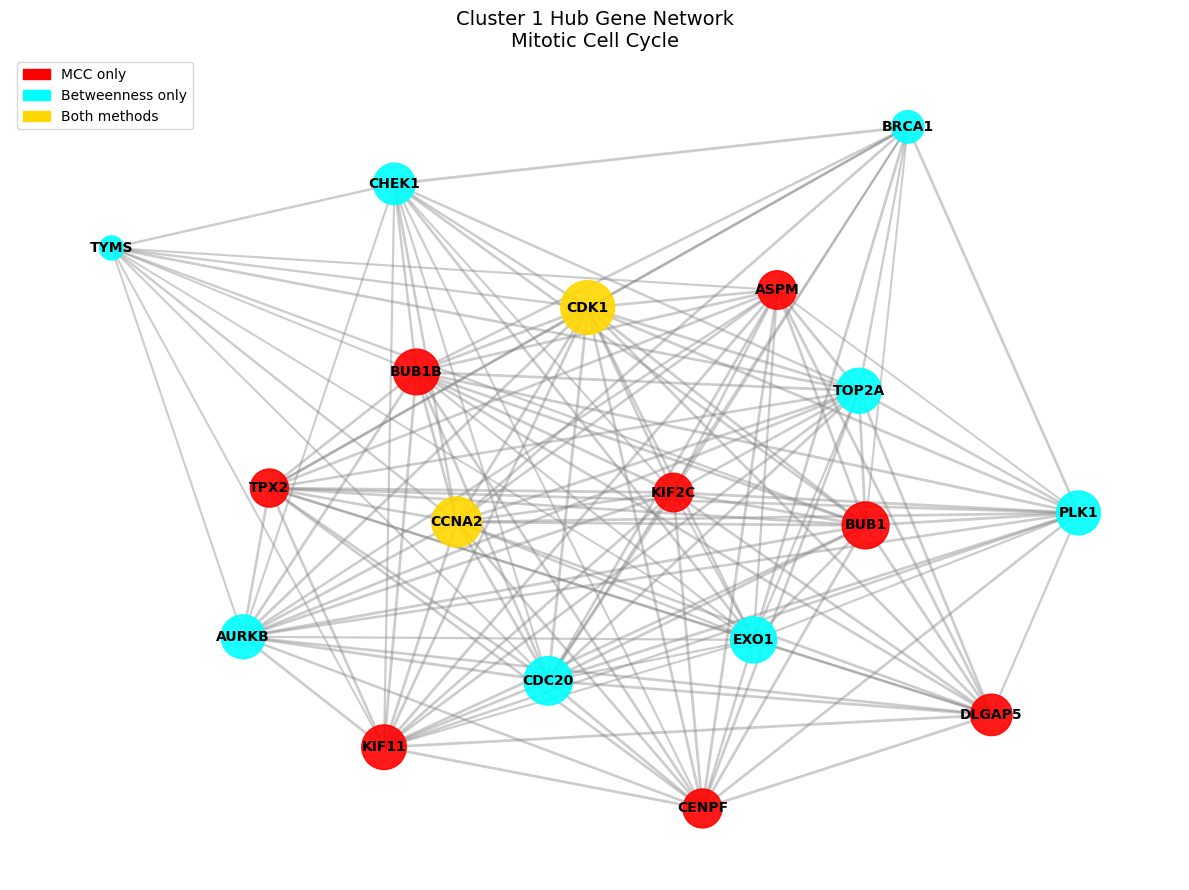

In [41]:
degrees_c1 = pd.read_csv('./results/PPI/cluster1_degrees.tsv', sep='\t')

# Define hub genes and method
mcc_only = set(mcc_genes_c1) - set(betweenness_genes_c1)
betweenness_only = set(betweenness_genes_c1) - set(mcc_genes_c1)
both = set(mcc_genes_c1) & set(betweenness_genes_c1)

all_hubs = set(mcc_genes_c1) | set(betweenness_genes_c1)

# Filter edges to hub genes only
hub_edges = edges_c1[
    (edges_c1['#node1'].isin(all_hubs)) & 
    (edges_c1['node2'].isin(all_hubs))
]

# Build network
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

G = nx.Graph()
for _, row in hub_edges.iterrows():
    G.add_edge(row['#node1'], row['node2'], weight=row['combined_score'])

# Color by method
color_map = []
for node in G.nodes():
    if node in both:
        color_map.append('gold')
    elif node in mcc_only:
        color_map.append('red')
    else:
        color_map.append('cyan')

# Node sizes by degree
node_sizes = []
for node in G.nodes():
    deg = degrees_c1[degrees_c1['#node'] == node]['node_degree'].values
    node_sizes.append(deg[0] * 100 if len(deg) > 0 else 500)

# Edge weights
edge_weights = [G[u][v]['weight'] * 2 for u, v in G.edges()]

degrees = [degrees_c1[degrees_c1['#node'] == node]['node_degree'].values[0] 
           for node in G.nodes()]

# Normalize to range 300-1500
min_deg, max_deg = min(degrees), max(degrees)
node_sizes = [300 + (d - min_deg) / (max_deg - min_deg) * 1200 for d in degrees]

# Plot
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G, seed=42, k=2)

nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_edges(G, pos, width=edge_weights, alpha=0.4, edge_color='grey')
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

legend = [mpatches.Patch(color='red', label='MCC only'),
          mpatches.Patch(color='cyan', label='Betweenness only'),
          mpatches.Patch(color='gold', label='Both methods')]
plt.legend(handles=legend, loc='upper left')

plt.title('Cluster 1 Hub Gene Network\nMitotic Cell Cycle', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('./figures/cluster1_hub_network.png', dpi=150)
plt.show()